# 01 · Base de conhecimento da Zela

**Objetivo:** montar e inspecionar a base que fundamenta as respostas da IA.

- 19 fontes públicas (Prefeitura de SP, Câmara Municipal, Governo de SP, CTB) + 1 documento interno da equipe.
- Cada fonte foi lida e **dividida em trechos curtos e autocontidos** (1 ideia por trecho, 1–4 frases), reescritos
  em linguagem simples e sempre ligados ao `id_fonte`. Trecho pequeno = busca mais precisa e citação verificável.
- Atos oficiais (leis, decretos) são domínio público (Lei 9.610/98, art. 8º, IV). Páginas institucionais da PMSP
  são usadas para fim educacional, com citação da fonte.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src")); sys.path.insert(0, os.path.abspath("../scripts"))
import pandas as pd
from zela.base import carregar_fontes, carregar_trechos
from zela.config import DIR_BASE

fontes = pd.DataFrame(carregar_fontes().values())
trechos = pd.DataFrame([t.__dict__ for t in carregar_trechos()])
print(f"{len(fontes)} fontes · {len(trechos)} trechos")

19 fontes · 47 trechos


## Tabela da base (fonte, formato, licença, nº de trechos)

In [2]:
n = trechos.groupby("fonte").size().rename("n_trechos")
tabela = fontes.merge(n, left_on="id_fonte", right_index=True, how="left").fillna({"n_trechos": 0})
tabela = tabela[["id_fonte", "titulo", "orgao", "formato", "licenca", "n_trechos", "url"]]
tabela["n_trechos"] = tabela["n_trechos"].astype(int)
display(tabela)

md = "| Fonte | Título | Órgão | Formato | Licença | Nº trechos |\n|---|---|---|---|---|---|\n"
for _, r in tabela.iterrows():
    md += f"| {r.id_fonte} | [{r.titulo}]({r.url}) | {r.orgao} | {r.formato} | {r.licenca} | {r.n_trechos} |\n"
md += f"| **Total** | | | | | **{tabela.n_trechos.sum()}** |\n"
(DIR_BASE / "tabela_base.md").write_text(md, encoding="utf-8")
print("Tabela salva em base/tabela_base.md")

,id_fonte,titulo,orgao,formato,licenca,n_trechos,url
0,F01,Tapa Buraco (Zeladoria Urbana),Subprefeitura Sapopemba / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,6,https://prefeitura.sp.gov.br/web/sapopemba/w/z...
1,F02,Operacao Tapa-Buraco no Ipiranga: saiba como s...,Subprefeitura Ipiranga / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,3,https://prefeitura.sp.gov.br/web/ipiranga/w/op...
2,F03,Decreto Municipal n. 59.671 de 7 de agosto de ...,Prefeitura de Sao Paulo,PDF,Ato oficial - dominio publico (Lei 9.610/98 ar...,7,https://saopaulo.sp.leg.br/iah/fulltext/decret...
3,F04,Iluminacao publica - perguntas frequentes,SP Regula / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,5,https://prefeitura.sp.gov.br/web/spregula/ilum...
4,F05,Solicitar manutencao para iluminacao publica a...,SP Regula / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,1,https://prefeitura.sp.gov.br/web/spregula/w/il...
5,F06,Iluminacao publica - como solicitar manutencao,SP Regula / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,1,https://prefeitura.sp.gov.br/web/spregula/w/il...
6,F07,Saiba como solicitar nossos servicos de poda e...,Subprefeitura Butanta / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,3,https://prefeitura.sp.gov.br/web/butanta/w/sai...
7,F08,Manutencao e limpeza de bocas de lobo galerias...,Subprefeitura Santana/Tucuruvi / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,1,https://prefeitura.sp.gov.br/web/santana_tucur...
8,F09,Rua e bairro - lista de servicos,Secretaria Municipal das Subprefeituras / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,2,https://prefeitura.sp.gov.br/web/subprefeitura...
9,F10,Calcadas - especificacoes tecnicas,Secretaria Municipal das Subprefeituras / PMSP,HTML,Conteudo institucional publico da PMSP - uso e...,2,https://prefeitura.sp.gov.br/web/subprefeitura...


Tabela salva em base/tabela_base.md


## Distribuição por categoria e tamanho dos trechos

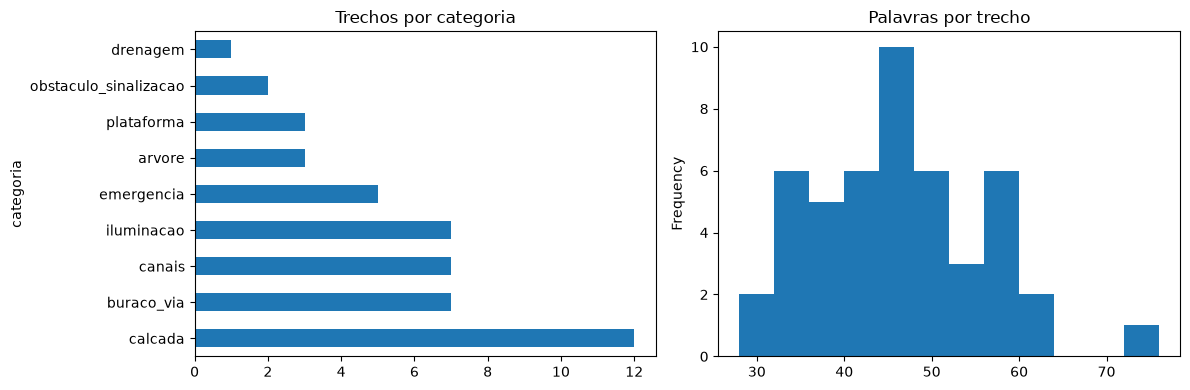

count    47.000000
mean     45.829787
std       9.856181
min      28.000000
25%      38.500000
50%      45.000000
75%      51.500000
max      76.000000
Name: palavras, dtype: float64

In [3]:
import matplotlib.pyplot as plt
trechos["palavras"] = trechos.texto.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
trechos.categoria.value_counts().plot.barh(ax=ax[0], title="Trechos por categoria")
trechos.palavras.plot.hist(ax=ax[1], bins=12, title="Palavras por trecho")
plt.tight_layout(); plt.show()
trechos.palavras.describe()

## Exemplo de trecho

In [4]:
trechos.sample(3, random_state=1)[["id", "fonte", "categoria", "titulo", "texto"]]

,id,fonte,categoria,titulo,texto
24,T025,F10,calcada,Padrão técnico do piso da calçada,"A calçada deve ter superfície regular, contínu..."
22,T023,F09,calcada,Serviços do SP156 para calçadas,Na categoria 'Rua e bairro' do SP156 existem s...
39,T040,F11,emergencia,Ruas alagadas,"Não atravesse ruas alagadas a pé ou de carro, ..."
